# Как работают первые слои LISA
### От 208 датчиков к 25 ветвям — через рисунки и проверяемые вычисления

**Главный вопрос:** что такое «270 каналов на сферических гармониках», если датчиков всего 208?

Это **270 разных смесей одних и тех же 208 сигналов**. Мы сначала соберём такую смесь вручную,
затем построим карты весов на шлеме и пройдём весь интерпретируемый входной блок.

**Маршрут (~60–90 минут):**
1. Один виртуальный канал: взвешенная сумма.
2. Положения датчиков и сферические гармоники.
3. 270 карт внимания и проверка того, что они не зависят от сигнала.
4. Общее перемешивание, индивидуальный слой и временные фильтры.
5. Мини-обучение коэффициентов гармоник и игрушечная калибровка нового человека.
6. Проверка на реальном коде LISA.

**Как запускать:** выбери Python из `.venv` проекта FQW и выполни **Run All**.
В блокноте уже сохранены результаты выполнения. Для опытов меняй параметры соответствующей ячейки и запускай её снова.
Сеть, GPU, МЭГ-файлы и обученные веса не нужны. Основные опыты используют numpy, matplotlib и torch. Необязательная сверка в §14 использует локальный код LISA и рабочую SciPy.

> Здесь **синтетические сигналы, условная геометрия и демонстрационные веса**. Эти рисунки не являются результатами исследования мозга.
> Размеры основного примера соответствуют рассматриваемой конфигурации LISA, но сами числа 208, 270 и 25 не универсальны.

In [1]:
from pathlib import Path
import sys
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'code/LISA/src/lisa/model/nn_modules.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Открой блокнот из папки FQW или её подпапки.')
sys.path.insert(0, str(ROOT / 'code/LISA/src'))

def softmax(a, axis=-1):
    exp_a = np.exp(a - np.max(a, axis=axis, keepdims=True))
    return exp_a / exp_a.sum(axis=axis, keepdims=True)

SEED = 17
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False})
M, J, K, T, FS = 208, 270, 25, 300, 100
L = 8  # учебное число степеней: 0,...,L-1; в основной конфигурации статьи L=24
seconds = np.arange(T) / FS
print(f'Датчики M={M}; виртуальные каналы J={J}; ветви K={K}; время T={T}.')

Датчики M=208; виртуальные каналы J=270; ветви K=25; время T=300.


## 1. Один виртуальный канал можно посчитать вручную

Пусть есть всего три датчика. В момент времени $t$ они показывают $x(t)=[2,-1,4]$.
Для одного выходного канала выберем веса $c=[0.6,0.3,0.1]$:

$$y(t)=0.6\cdot2+0.3\cdot(-1)+0.1\cdot4=1.3.$$

Один новый канал — одна новая **временная кривая**. К каждому моменту времени применяется тот же рецепт.
Для двух каналов нужны два рецепта; для 270 — 270 рецептов. Новые физические точки на шлеме не появляются.

Вход: [ 2. -1.  4.]
Два виртуальных канала: [1.3 2.8]


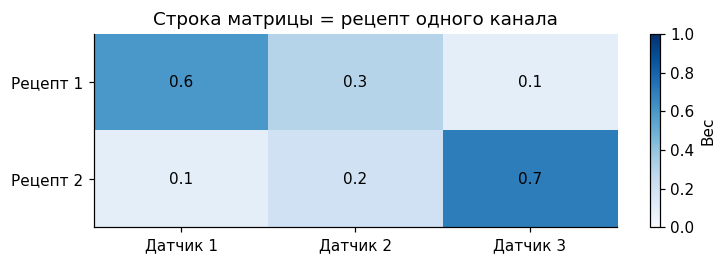

In [2]:
toy_x = np.array([2., -1., 4.])
toy_c = np.array([[.6, .3, .1], [.1, .2, .7]])
print('Вход:', toy_x)
print('Два виртуальных канала:', toy_c @ toy_x)
assert np.isclose((toy_c @ toy_x)[0], 1.3)

fig, ax = plt.subplots(figsize=(7, 2.5))
im = ax.imshow(toy_c, vmin=0, vmax=1, cmap='Blues', aspect='auto')
for j in range(2):
    for i in range(3): ax.text(i, j, f'{toy_c[j,i]:.1f}', ha='center', va='center')
ax.set(xticks=range(3), xticklabels=['Датчик 1', 'Датчик 2', 'Датчик 3'],
       yticks=range(2), yticklabels=['Рецепт 1', 'Рецепт 2'], title='Строка матрицы = рецепт одного канала')
fig.colorbar(im, ax=ax, label='Вес'); plt.tight_layout(); plt.show()

## 2. На сфере находятся 208 датчиков

Расположим точки на сферической шапке. Это **синтетический шлем**, не геометрия реального прибора.
Сферические координаты: $\theta$ — полярный угол от оси $z$ (не географическая широта),
$\varphi$ — азимут вокруг неё. В рассматриваемой параметризации гармоникам нужны углы; радиус не используется.

На следующих картах точки всегда обозначают **те же 208 датчиков**. Цвет точки будет меняться, положение — нет.

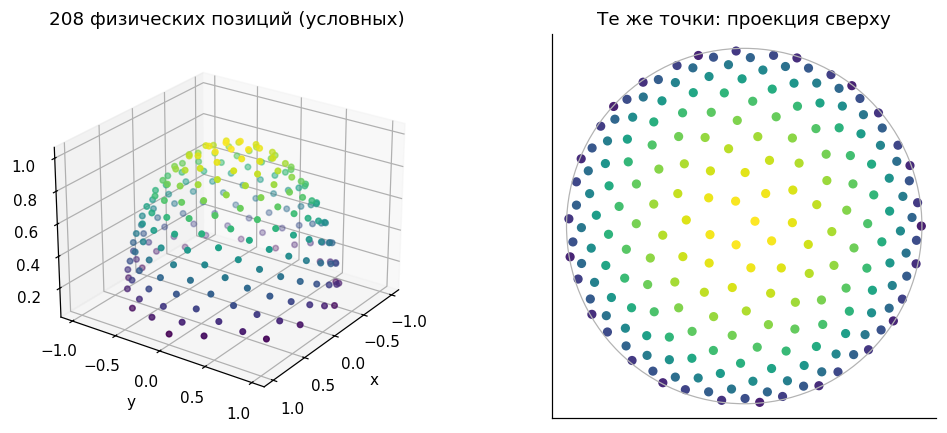

In [3]:
n = np.arange(M)
z = 0.08 + 0.92 * (n + .5) / M
phi = n * np.pi * (3 - np.sqrt(5))
coords = np.column_stack([np.sqrt(1-z*z)*np.cos(phi), np.sqrt(1-z*z)*np.sin(phi), z])
theta = np.arccos(z)
phi = np.arctan2(coords[:,1], coords[:,0])
xy_scaled = (coords[:,:2] + 1) / 2

def sensor_map(ax, values, title, signed=False):
    limit = max(float(np.max(np.abs(values))), 1e-12)
    im = ax.scatter(coords[:,0], coords[:,1], c=values, s=25,
                    cmap='RdBu_r' if signed else 'viridis',
                    vmin=-limit if signed else 0, vmax=limit)
    ax.add_patch(plt.Circle((0,0), 1, fill=False, color='.7', lw=.8))
    ax.set(aspect='equal', title=title, xlim=(-1.08,1.08), ylim=(-1.08,1.08))
    ax.set_xticks([]); ax.set_yticks([])
    return im

fig = plt.figure(figsize=(10,4))
ax = fig.add_subplot(121, projection='3d')
ax.scatter(*coords.T, c=coords[:,2], cmap='viridis', s=13)
ax.set(xlabel='x', ylabel='y', zlabel='z', title='208 физических позиций (условных)')
ax.view_init(25,35)
ax = fig.add_subplot(122)
sensor_map(ax, z, 'Те же точки: проекция сверху')
plt.tight_layout(); plt.show()

## 3. Гармоники — готовые пространственные узоры

$Y_\ell^m(\theta,\varphi)$ — функция на сфере. У степени $\ell$ есть $2\ell+1$ гармоник.
Если $\ell=0,\ldots,L-1$, всего их $L^2$.
Низкие степени описывают широкие изменения, высокие позволяют добавлять мелкие детали.

В отличие от коэффициентов смеси, **сами гармоники не обучаются**.
Мы вычисляем их значения в точках датчиков и получаем матрицу $B$ размера $L^2\times208$.
Каждая строка — один узор, каждый столбец — один датчик.

Ниже используется вещественный базис, согласованный с локальной реализацией LISA;
разные библиотеки могут выбирать другие знаки или порядок функций. Используем рекурсию на NumPy, чтобы основные опыты не зависели от SciPy.

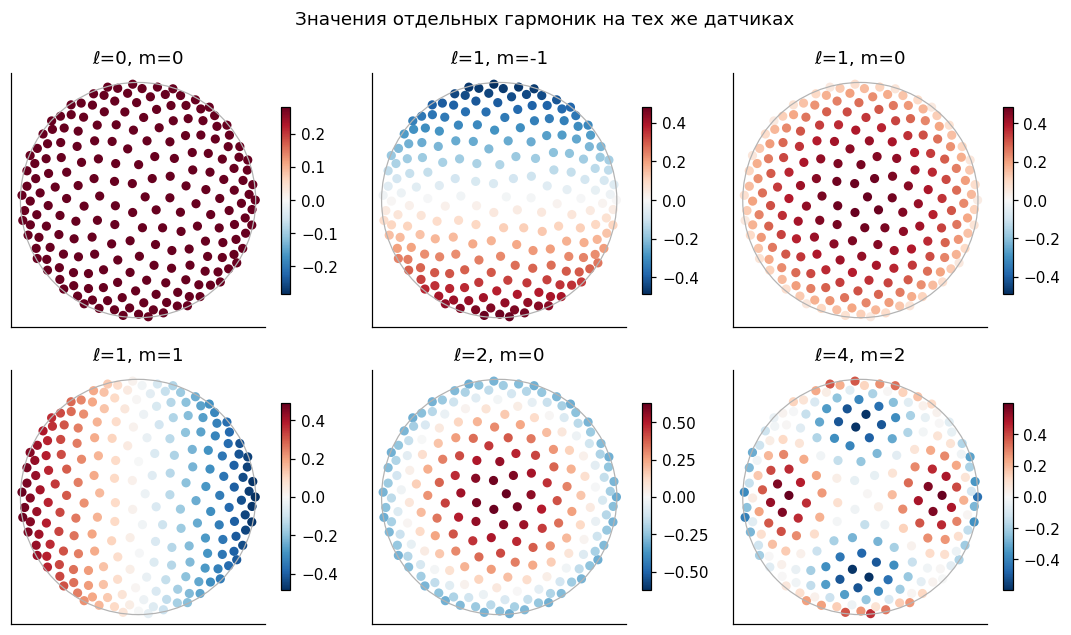

B: (64, 208) — базисные функции × датчики


In [4]:
def associated_legendre(degree, order, x):
    # P_m^m, затем P_{m+1}^m и рекурсия по степени; фаза Кондона–Шортли.
    pmm = np.ones_like(x)
    for k in range(1, order+1):
        pmm *= -(2*k-1) * np.sqrt(np.maximum(0, 1-x*x))
    if degree == order:
        return pmm
    prev, current = pmm, x*(2*order+1)*pmm
    for ell in range(order+2,degree+1):
        prev, current = current, ((2*ell-1)*x*current-(ell+order-1)*prev)/(ell-order)
    return current

def harmonic_basis(n_degrees):
    rows, labels = [], []
    for degree in range(n_degrees):
        for order in range(-degree, degree+1):
            m = abs(order)
            norm = np.sqrt((2*degree+1)/(4*np.pi) *
                           np.exp(math.lgamma(degree-m+1)-math.lgamma(degree+m+1)))
            value = norm * associated_legendre(degree,m,np.cos(theta))
            if order > 0: value = value * np.sqrt(2) * np.cos(m*phi)
            if order < 0: value = value * np.sqrt(2) * np.sin(m*phi)
            rows.append(value)
            labels.append((degree, order))
    return np.array(rows), labels

B, labels = harmonic_basis(L)
fig, axes = plt.subplots(2,3,figsize=(10,6))
for ax, label in zip(axes.flat, [(0,0),(1,-1),(1,0),(1,1),(2,0),(4,2)]):
    im = sensor_map(ax, B[labels.index(label)], f'ℓ={label[0]}, m={label[1]}', signed=True)
    fig.colorbar(im, ax=ax, shrink=.65)
fig.suptitle('Значения отдельных гармоник на тех же датчиках')
plt.tight_layout(); plt.show()
print('B:', B.shape, '— базисные функции × датчики')

## 4. От смеси узоров к одному рецепту

Для одного виртуального канала обучается вектор $\gamma_j$ из $L^2$ коэффициентов:

$$a_j=\gamma_j B,\qquad C_{ji}=\operatorname{softmax}_i(a_j),\qquad y_j(t)=\sum_i C_{ji}x_i(t).$$

- $a_j$ — ненормированные оценки (могут иметь любой знак).
- $C_j$ — положительные веса, сумма которых равна 1.
- $y_j$ — временной сигнал, который получится после применения весов к данным.

**Опыт:** поменяй `amplitude` с 0 на 1, 4 и 10. При нуле softmax даёт равные веса.
При увеличении амплитуды положительного контраста распределение становится более сосредоточенным.
Цветовые шкалы на рисунках разные: значение гармоники и вес датчика — разные величины.

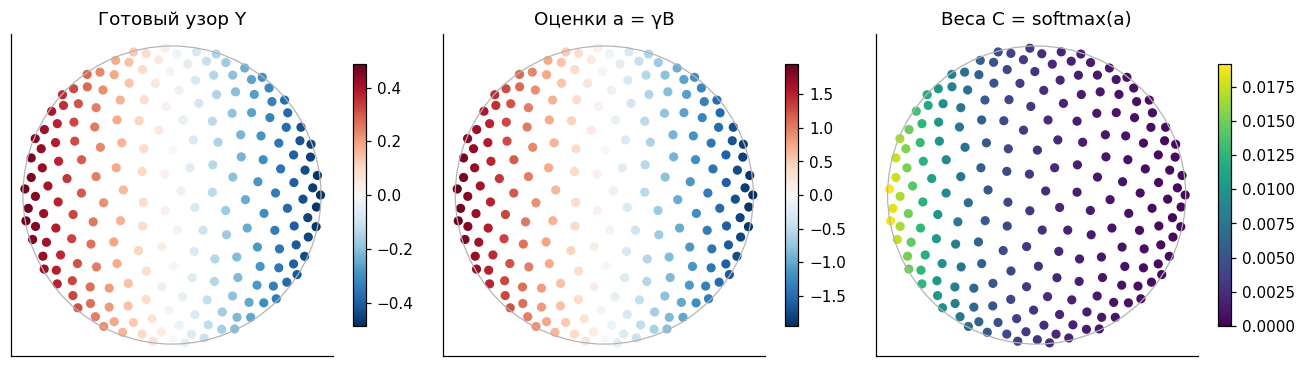

Сумма весов: 1.000000; min=0.00040; max=0.01915
Эффективное число учитываемых датчиков (1/Σc²): 103.4


In [5]:
amplitude = 4.0  # МЕНЯЙ: 0, 1, 4, 10
selected_harmonic = (1, 1)
gamma_one = np.zeros(L*L)
gamma_one[labels.index(selected_harmonic)] = amplitude
logits_one = gamma_one @ B
weights_one = softmax(logits_one)
fig, axes = plt.subplots(1,3,figsize=(12,3.7))
for ax, values, title, signed in zip(axes,
        [B[labels.index(selected_harmonic)], logits_one, weights_one],
        ['Готовый узор Y', 'Оценки a = γB', 'Веса C = softmax(a)'], [True,True,False]):
    im = sensor_map(ax, values, title, signed)
    fig.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.show()
print(f'Сумма весов: {weights_one.sum():.6f}; min={weights_one.min():.5f}; max={weights_one.max():.5f}')
print('Эффективное число учитываемых датчиков (1/Σc²):', round(1 / np.sum(weights_one**2), 1))
assert np.allclose(softmax(np.zeros(M)), np.ones(M)/M)
assert np.allclose(softmax(logits_one+7), weights_one)  # общий сдвиг ничего не меняет

## 5. 270 виртуальных каналов = 270 карт на одном шлеме

Соберём коэффициенты в матрицу $\Gamma$ размера $270\times L^2$:

$$C=\operatorname{softmax}_{\text{датчики}}(\Gamma B),\qquad Y=CX.$$

Матрица $C$ имеет размер **270 × 208**. Строки — выходные каналы, столбцы — реальные датчики.
Для наглядности зададим несколько направленных карт вручную, остальные — случайно.
**Все веса в этом разделе демонстрационные, они ещё не обучены.**

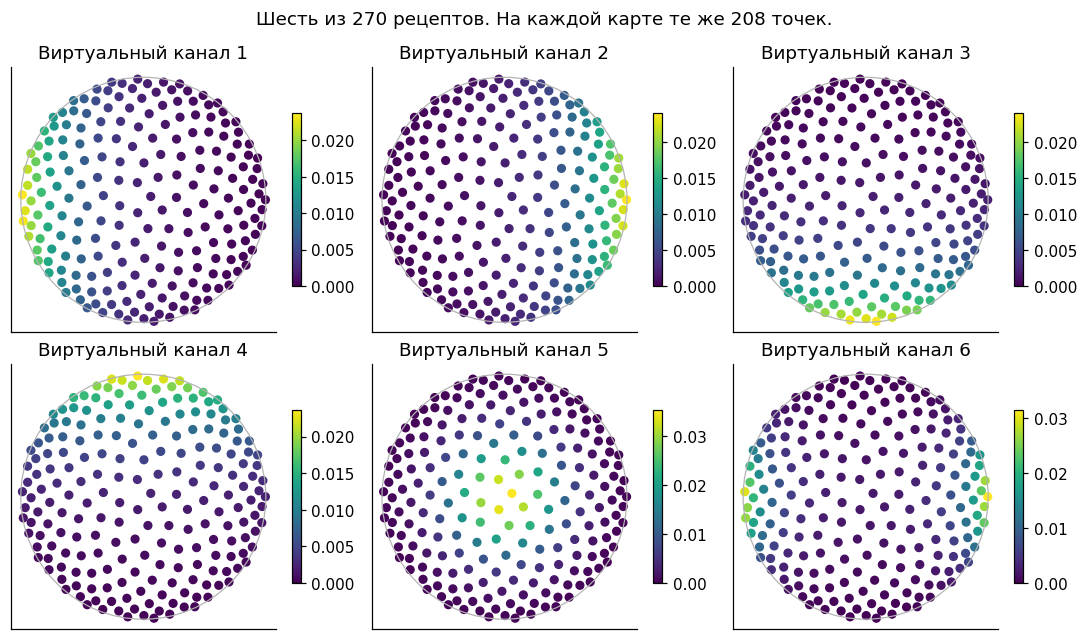

Γ: (270, 64) B: (64, 208) C: (270, 208)


In [6]:
rng_maps = np.random.default_rng(SEED)
Gamma = rng_maps.normal(0, .18, size=(J,L*L))
for j, (label, sign) in enumerate([((1,1),1),((1,1),-1),((1,-1),1),((1,-1),-1),((2,0),1),((2,2),1)]):
    Gamma[j] = 0
    Gamma[j, labels.index(label)] = 5 * sign
C = softmax(Gamma @ B, axis=1)
fig, axes = plt.subplots(2,3,figsize=(10,6))
for j, ax in enumerate(axes.flat):
    im = sensor_map(ax, C[j], f'Виртуальный канал {j+1}')
    fig.colorbar(im, ax=ax, shrink=.6)
fig.suptitle('Шесть из 270 рецептов. На каждой карте те же 208 точек.')
plt.tight_layout(); plt.show()
print('Γ:', Gamma.shape, 'B:', B.shape, 'C:', C.shape)
assert C.shape == (J,M)
assert np.allclose(C.sum(axis=1), 1)

## 6. Пропускаем временные сигналы через карты

Создадим два скрытых сигнала с частотами 5 и 12 Гц и разными пространственными паттернами.
Датчики измеряют их смесь плюс шум: $X=GS+\varepsilon$.
Матрица $G$ здесь придумана для обучения; это **не биофизическая forward-модель МЭГ**.

Обрати внимание: карты $C$ одинаковы для всех моментов времени. После обучения и при фиксированной геометрии
это статическое пространственное преобразование. В обучающем режиме spatial dropout может дополнительно маскировать датчики;
в нашем примере он отключён.

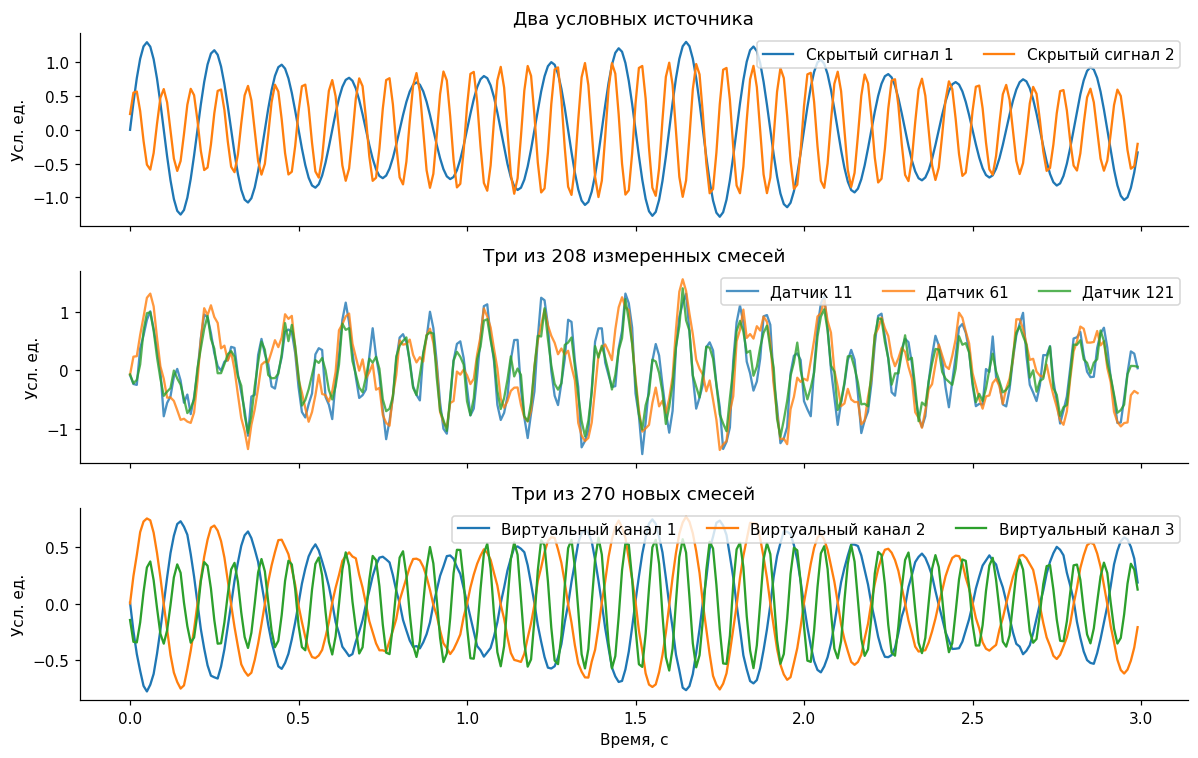

X: (208, 300) → Y: (270, 300)


In [7]:
sources = np.stack([
    np.sin(2*np.pi*5*seconds)*(1+.3*np.cos(2*np.pi*.6*seconds)),
    np.sin(2*np.pi*12*seconds+.4)*(0.6+.4*np.sin(np.pi*seconds/3)**2)
])
G = np.column_stack([coords[:,0], coords[:,1]])
X = G @ sources + np.random.default_rng(SEED+1).normal(0,.12,size=(M,T))
Y = C @ X
fig, axes = plt.subplots(3,1,figsize=(11,7),sharex=True)
for k in range(2): axes[0].plot(seconds,sources[k],label=f'Скрытый сигнал {k+1}')
for i in [10,60,120]: axes[1].plot(seconds,X[i],label=f'Датчик {i+1}',alpha=.8)
for j in [0,1,2]: axes[2].plot(seconds,Y[j],label=f'Виртуальный канал {j+1}')
for ax, title in zip(axes,['Два условных источника','Три из 208 измеренных смесей','Три из 270 новых смесей']):
    ax.set(ylabel='Усл. ед.',title=title); ax.legend(loc='upper right',ncol=3)
axes[-1].set_xlabel('Время, с'); plt.tight_layout(); plt.show()
print('X:', X.shape, '→ Y:', Y.shape)
assert np.allclose(C @ (2*X), 2*Y)  # линейность по сигналу
assert np.allclose(Y[0], (C[0,:,None]*X).sum(axis=0))

## 7. Почему 270 каналов не дают 270 независимых измерений

При фиксированных весах $Y=CX$, поэтому $\operatorname{rank}(Y)\leq\operatorname{rank}(X)\leq208$.
Больше выходных каналов — больше смесей, но не новая измеренная информация.
У первых шести карт низкие степени гармоник, поэтому часть смесей похожа; другие карты могут сильно отличаться.

**Не путай количество гармоник и каналов.** При $L=24$ на канал приходится 576 коэффициентов:
это *больше* 208 свободных весов. Такая параметризация сама по себе не является сжатием числа параметров.
Низкие степени ограничивают пространственную детализацию; высокие степени и softmax допускают резкие карты.
Гарантии «все карты обязательно гладкие» нет.

Число строк X / Y: 208 / 270
Численный ранг X / Y: 208 / 208
При L=8: 17,280 коэффициентов Γ.
При L=24: 155,520 коэффициентов Γ против 56,160 элементов свободной C.


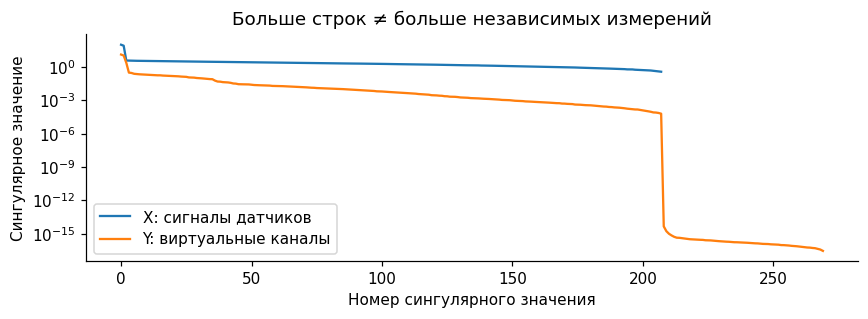

In [8]:
rank_x, rank_y = np.linalg.matrix_rank(X), np.linalg.matrix_rank(Y)
print('Число строк X / Y:', X.shape[0], '/', Y.shape[0])
print('Численный ранг X / Y:', rank_x, '/', rank_y)
print(f'При L={L}: {J*L*L:,} коэффициентов Γ.')
print(f'При L=24: {J*24*24:,} коэффициентов Γ против {J*M:,} элементов свободной C.')
assert rank_y <= rank_x
fig, ax = plt.subplots(figsize=(8,3))
ax.semilogy(np.linalg.svd(X,compute_uv=False),label='X: сигналы датчиков')
ax.semilogy(np.linalg.svd(Y,compute_uv=False),label='Y: виртуальные каналы')
ax.set(xlabel='Номер сингулярного значения',ylabel='Сингулярное значение',title='Больше строк ≠ больше независимых измерений')
ax.legend(); plt.tight_layout(); plt.show()

## 8. Следующий слой: общее перемешивание 270 → 270

Свёртка **1×1** в этой части сети в каждый момент времени умножает вектор каналов на матрицу:

$$U(t)=W_uY(t)+b_u.$$

Её ядро имеет длину 1 по времени: соседние моменты пока не используются.
В отличие от $C$, веса $W_u$ могут быть **отрицательными**: слой умеет вычитать каналы.
Ниже первые два выхода вычисляют разности противоположных карт, остальные оставлены неизменными.
Это ручная иллюстрация; в LISA матрица общая для людей и обучается вместе с сетью.

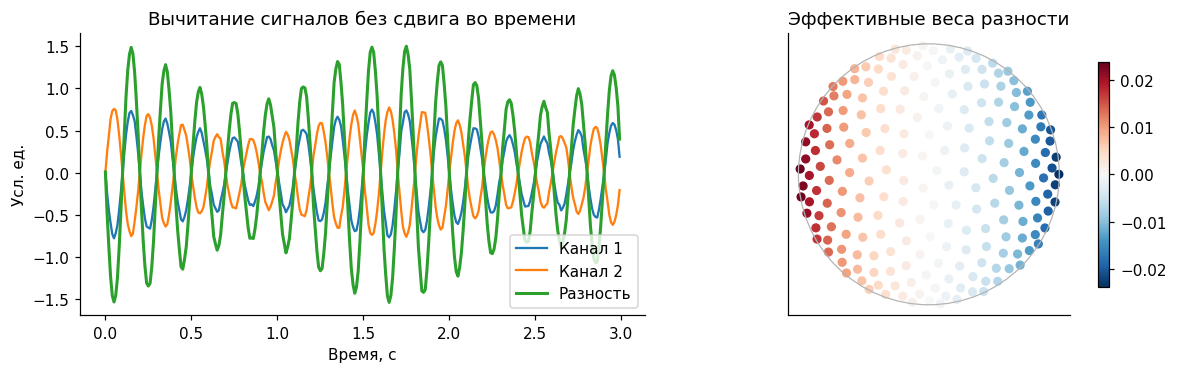

In [9]:
Wu = np.eye(J)
Wu[0] = 0; Wu[0,0] = 1; Wu[0,1] = -1
Wu[1] = 0; Wu[1,2] = 1; Wu[1,3] = -1
bu = np.zeros(J)  # в настоящем слое bias обучаемый, здесь выбран нулевым
U = Wu @ Y + bu[:,None]
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(seconds,Y[0],label='Канал 1'); axes[0].plot(seconds,Y[1],label='Канал 2')
axes[0].plot(seconds,U[0],label='Разность',lw=2); axes[0].legend()
axes[0].set(xlabel='Время, с',ylabel='Усл. ед.',title='Вычитание сигналов без сдвига во времени')
im = sensor_map(axes[1], (Wu @ C)[0], 'Эффективные веса разности', signed=True)
fig.colorbar(im,ax=axes[1],shrink=.8); plt.tight_layout(); plt.show()

## 9. Индивидуальный слой: 270 → 25

Для человека $s$ выбирается своя матрица $W_s$ размера $25\times270$:

$$V_s=W_sU.$$

Она тоже работает независимо в каждый момент времени. Здесь появляются 25 **ветвей**, к которым затем
применяются отдельные временные фильтры. Ветвь — вычислительный канал, а не автоматически доказанный отдельный нейронный источник.

В одной модели $C$ и $W_u$ общие, а $W_s$ различается между людьми. Именно эту матрицу можно
дообучать при калибровке нового человека. В примере две матрицы придуманы вручную:
одна меняет усиление первой ветви, поэтому при **одном и том же входе** выходы отличаются.

Индивидуальные параметры: (25, 270) = 6750 чисел на человека
Эффективный пространственный фильтр: (25, 208)


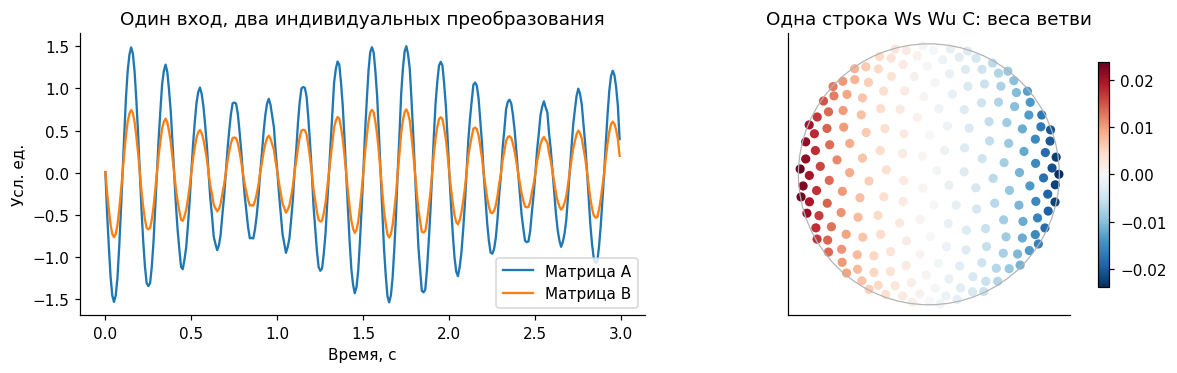

In [10]:
Ws_A = np.zeros((K,J))
Ws_A[np.arange(K),np.arange(K)] = 1
Ws_B = Ws_A.copy(); Ws_B[0] *= .5
V_A, V_B = Ws_A @ U, Ws_B @ U
Weff = Ws_A @ Wu @ C
beff = Ws_A @ bu
assert np.allclose(V_A, Weff @ X + beff[:,None])
print('Индивидуальные параметры:', Ws_A.shape, '=', Ws_A.size, 'чисел на человека')
print('Эффективный пространственный фильтр:', Weff.shape)
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(seconds,V_A[0],label='Матрица A')
axes[0].plot(seconds,V_B[0],label='Матрица B')
axes[0].set(title='Один вход, два индивидуальных преобразования',xlabel='Время, с',ylabel='Усл. ед.')
axes[0].legend()
im = sensor_map(axes[1],Weff[0],'Одна строка Ws Wu C: веса ветви',signed=True)
fig.colorbar(im,ax=axes[1],shrink=.8); plt.tight_layout(); plt.show()

## 10. Временной фильтр: теперь используются соседние моменты

До этого смешивались **каналы в один момент**. Теперь каждая ветвь отдельно смешивает **15 соседних отсчётов**.
При 100 Гц длину ядра обычно описывают как 150 мс (между центрами крайних отсчётов — 140 мс).
В LISA это depthwise Conv1d: свой фильтр на ветвь, без перемешивания ветвей на этом этапе.

Покажем усредняющий фильтр: он уменьшает быстрые колебания. **Это выбранный нами пример ядра**, а не выученный фильтр статьи.
PyTorch Conv1d фактически вычисляет взаимную корреляцию; для симметричного ядра ниже это совпадает со свёрткой.
Используется двустороннее дополнение нулями, поэтому крайние отсчёты имеют граничные эффекты.
Такая фильтрация с `padding='same'` не является причинной обработкой для потока в реальном времени.

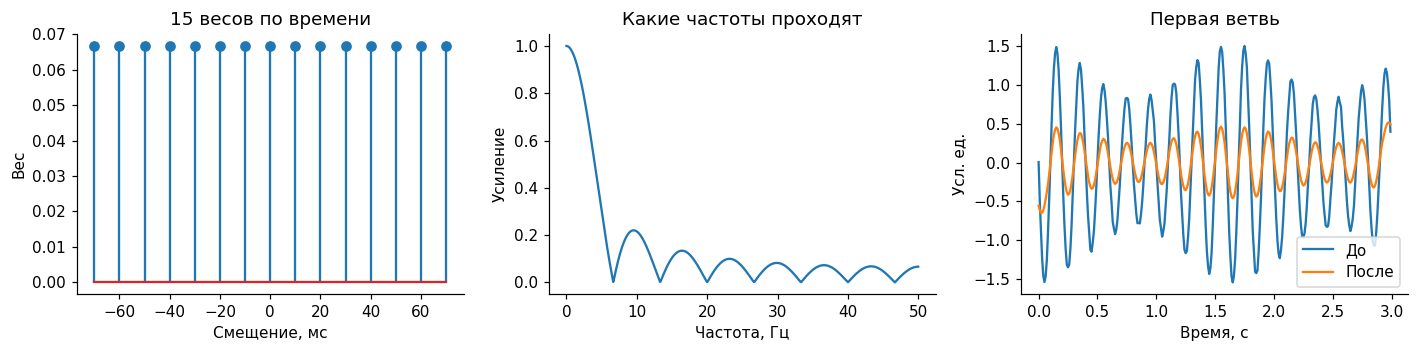

In [11]:
H = np.zeros((K,15)); H[:,7] = 1  # остальные ветви пока пропускаем без изменений
H[0] = np.ones(15)/15
Z = F.conv1d(torch.tensor(V_A[None],dtype=torch.float64),
             torch.tensor(H[:,None],dtype=torch.float64),padding=7,groups=K)[0].numpy()
freq = np.linspace(0,FS/2,512)
response = np.exp(-2j*np.pi*freq[:,None]/FS*np.arange(15)) @ H[0]
fig, axes = plt.subplots(1,3,figsize=(13,3.3))
axes[0].stem((np.arange(15)-7)*10,H[0]); axes[0].set(title='15 весов по времени',xlabel='Смещение, мс',ylabel='Вес')
axes[1].plot(freq,np.abs(response)); axes[1].set(title='Какие частоты проходят',xlabel='Частота, Гц',ylabel='Усиление')
axes[2].plot(seconds,V_A[0],label='До'); axes[2].plot(seconds,Z[0],label='После')
axes[2].set(title='Первая ветвь',xlabel='Время, с',ylabel='Усл. ед.'); axes[2].legend()
plt.tight_layout(); plt.show()
assert Z.shape == V_A.shape
assert np.allclose(Z[1:],V_A[1:])

## 11. Вся цепочка и два вида линейности

| Этап | Вход → выход (без batch) | Что обучается | Общее между людьми? |
|---|---|---|---|
| 3D-внимание | 208×300 → 270×300 | коэффициенты гармоник Γ | Да |
| Перемешивание 1×1 | 270×300 → 270×300 | Wu и bias | Да |
| Индивидуальная проекция | 270×300 → 25×300 | Ws | Своя матрица на человека |
| Временные фильтры | 25×300 → 25×300 | 25 ядер по 15 весов | Да |

Матрица внимания нелинейно зависит от **параметров** из-за softmax. Но при фиксированных параметрах
она линейна по **входному сигналу**. До временных фильтров все три матрицы можно свернуть в одну:

$$V_s=(W_sW_uC)X+W_sb_u.$$

Из-за bias это в общем случае аффинное преобразование. Само название «unmixing» не гарантирует,
что выход уже точно разделён на физические источники.

В дальнейшем LISA использует нелинейные временные блоки и проекцию в пространство аудиоэмбеддингов.
Наш блокнот останавливается перед ними.

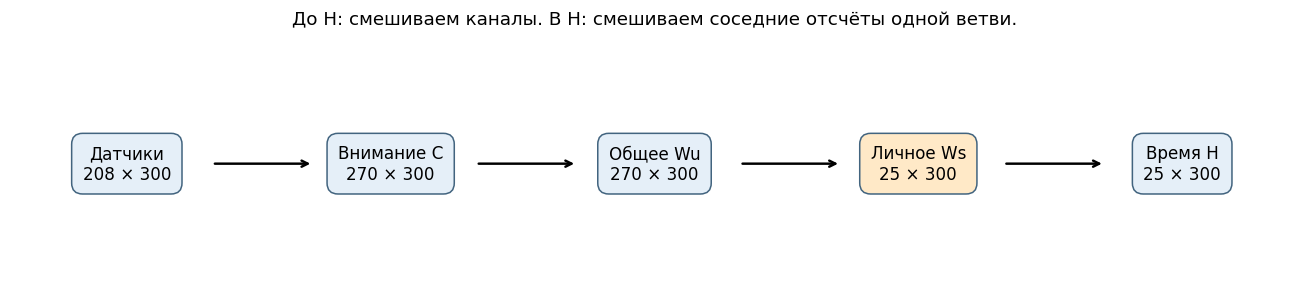

In [12]:
fig, ax = plt.subplots(figsize=(12,2.8))
ax.axis('off')
items = [('Датчики','208 × 300'),('Внимание C','270 × 300'),('Общее Wu','270 × 300'),('Личное Ws','25 × 300'),('Время H','25 × 300')]
for i,(name,shape) in enumerate(items):
    x = .09+i*.205
    ax.text(x,.5,name+'\n'+shape,transform=ax.transAxes,ha='center',va='center',fontsize=11,
            bbox=dict(boxstyle='round,pad=.65',fc='#e5eff8' if i!=3 else '#ffe9c7',ec='#42647f'))
    if i<4: ax.annotate('',xy=(x+.145,.5),xytext=(x+.066,.5),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',lw=1.6))
ax.set_title('До H: смешиваем каналы. В H: смешиваем соседние отсчёты одной ветви.',pad=12)
plt.tight_layout(); plt.show()

## 12. Что значит «коэффициенты гармоник обучаются»

Небольшая отдельная задача: подобрать одну карту так, чтобы её выход приближался к **известному синтетическому сигналу**.
Обучаются только коэффициенты $\gamma$, а базис остаётся фиксированным. На каждой итерации:

$\gamma\to a\to C\to y\to\text{ошибка}\to\text{градиент}\to\text{новая }\gamma$.

Ниже целевая карта специально построена тем же базисом, поэтому задача достижима.
По сигналам карта может быть неединственной: снижение ошибки не означает, что мы нашли единственную физически правильную топографию.

**В настоящей LISA цель другая:** совместное обучение сети по контрастивной задаче сопоставления МЭГ и аудиоэмбеддингов.
Этот мини-опыт объясняет механизм градиента, не воспроизводит обучение из статьи.

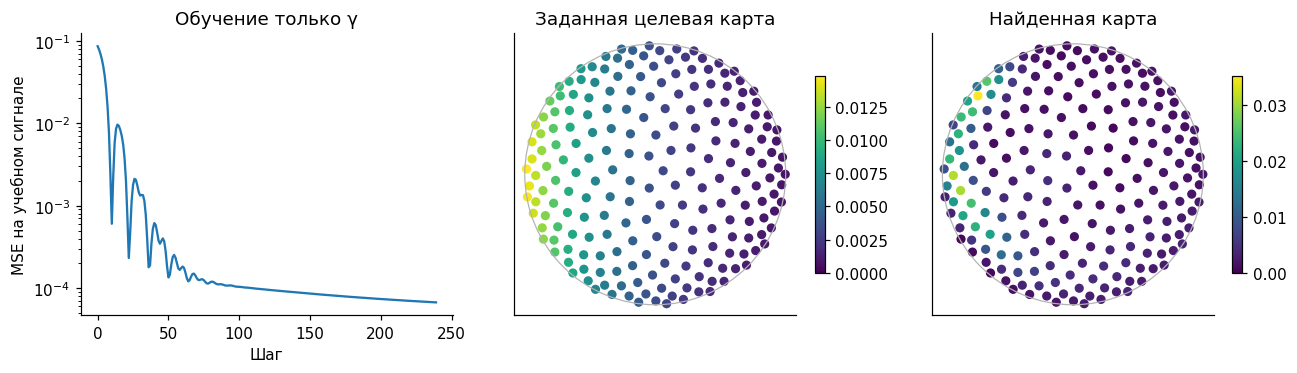

MSE: 0.085846 → 0.000067


In [13]:
torch.manual_seed(SEED)
basis_t = torch.tensor(B,dtype=torch.float32)
x_t = torch.tensor(X,dtype=torch.float32)
gamma_target = torch.zeros(L*L)
gamma_target[labels.index((1,1))] = 3
c_target = torch.softmax(gamma_target @ basis_t,dim=0)
target_y = (c_target @ x_t).detach()
gamma_train = torch.nn.Parameter(torch.zeros(L*L))
optimizer = torch.optim.Adam([gamma_train],lr=.04)
losses = []
for step in range(240):
    optimizer.zero_grad()
    c_train = torch.softmax(gamma_train @ basis_t,dim=0)
    pred_y = c_train @ x_t
    loss = ((pred_y-target_y)**2).mean()
    loss.backward(); optimizer.step()
    losses.append(loss.item())
with torch.no_grad():
    learned_c = torch.softmax(gamma_train @ basis_t,dim=0).numpy()
fig, axes = plt.subplots(1,3,figsize=(12,3.5))
axes[0].semilogy(losses); axes[0].set(title='Обучение только γ',xlabel='Шаг',ylabel='MSE на учебном сигнале')
for ax,values,title in [(axes[1],c_target.numpy(),'Заданная целевая карта'),(axes[2],learned_c,'Найденная карта')]:
    im=sensor_map(ax,values,title); fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout(); plt.show()
print(f'MSE: {losses[0]:.6f} → {losses[-1]:.6f}')
assert losses[-1] < losses[0]*.1

## 13. Зачем калибровать Ws: отдельный маленький опыт

У двух условных людей одни и те же два источника по-разному смешаны в измерениях.
Пусть общий блок сети уже выдал два признака $U_A=R_AS$, $U_B=R_BS$.
Матрица, которая восстанавливает источники у A, плохо работает у B.

Подберём новую матрицу **только по первой части записи B**, затем проверим на оставшейся части.
Здесь размер 2×2 вместо 25×270, чтобы механизм было видно. Решение получим методом наименьших квадратов.

> Для наглядности мы знаем истинные синтетические источники. В реальном эксперименте они неизвестны;
> при калибровке LISA используются пары МЭГ–аудио и задача retrieval. Этот опыт не оценивает качество реальной калибровки.

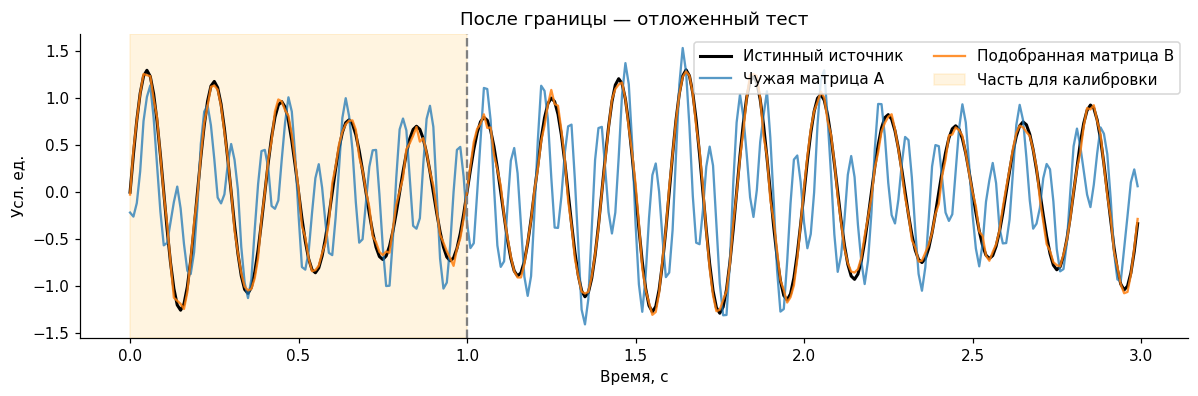

Ошибка на тестовой части: до 0.33829, после 0.00147


In [14]:
rng_cal = np.random.default_rng(SEED+2)
RA = np.array([[1,.25],[-.2,1.]])
RB = np.array([[.65,-.65],[.6,1.15]])
UA = RA @ sources
UB = RB @ sources + rng_cal.normal(0,.04,size=sources.shape)
W_A_small = np.linalg.inv(RA)
cut = 100  # калибровка: первая секунда; тест: две оставшиеся
W_B_small = np.linalg.lstsq(UB[:,:cut].T,sources[:,:cut].T,rcond=None)[0].T
before, after = W_A_small @ UB, W_B_small @ UB
mse_before = np.mean((before[:,cut:]-sources[:,cut:])**2)
mse_after = np.mean((after[:,cut:]-sources[:,cut:])**2)
fig, ax = plt.subplots(figsize=(11,3.7))
ax.plot(seconds,sources[0],color='black',label='Истинный источник',lw=2)
ax.plot(seconds,before[0],alpha=.75,label='Чужая матрица A')
ax.plot(seconds,after[0],alpha=.85,label='Подобранная матрица B')
ax.axvspan(0,cut/FS,color='orange',alpha=.12,label='Часть для калибровки')
ax.axvline(cut/FS,color='.5',ls='--'); ax.set(xlabel='Время, с',ylabel='Усл. ед.',title='После границы — отложенный тест')
ax.legend(ncol=2); plt.tight_layout(); plt.show()
print(f'Ошибка на тестовой части: до {mse_before:.5f}, после {mse_after:.5f}')
assert mse_after < mse_before

## 14. Сверяем с настоящими классами LISA

Если SciPy доступна, используем `Spatial3DAttentionLayer` и `SpatialModule` из **локального репозитория автора**.
Проверяем наш базис, матрицу внимания и весь проход с теми же демонстрационными весами.
Выбрана конфигурация без spatial dropout, gating и GELU во входном блоке;
временная свёртка с нулевым дополнением. Проверка не требует обученной модели.

В коде класса внимания аргумент `K` означает число степеней гармоник; в нашей записи это `L`.
Наш `K=25` означает число ветвей. Одинаковая буква в разных местах — возможный источник путаницы.

**Окружение:** при подготовке блокнота установленная SciPy 1.15.2 выдала ошибку загрузки
бинарного модуля на macOS 27. Если она сохраняется, ячейка сообщит о пропуске сверки.
Это не влияет на предыдущие опыты: они обходятся без SciPy. Исследовательское окружение не изменено.

In [15]:
try:
    from lisa.model.nn_modules import SpatialModule
except ImportError as error:
    print('Необязательная сверка пропущена: локальная SciPy/LISA не импортируется.')
    print('Причина:', str(error).splitlines()[0][:250])
    print('Все предыдущие учебные опыты работают независимо от SciPy.')
else:
    front = SpatialModule(
        n_input=M, n_attention=J, n_unmix=K, use_spatial_attention='3D',
        n_spatial_harmonics=L, coords_xy_scaled=xy_scaled,
        spatial_dropout_number=0, spatial_dropout_radius=0., coords_xyz=coords,
        temporal_filter_type='conv', temporal_filter_bands=None, temporal_filter_fs=FS,
        temporal_filter_freeze=False, temporal_filter_kernel_size=15,
        temporal_filter_padding_mode='zeros', tf_gated=False, tf_gate_per_channel=False,
        tf_gate_init_alpha=.5, tf_gelu=False, n_subjects=2, seed=SEED)
    front.eval()
    # Автор хранит L² функций в массиве (L,L) в порядке i=counter%L, j=counter//L.
    layout_original = front.self_attention._layout[0].numpy().transpose(1,0,2).reshape(L*L,M)
    basis_error = np.max(np.abs(B-layout_original))
    assert np.allclose(B,layout_original,atol=2e-5)
    with torch.no_grad():
        front.self_attention.Z.copy_(torch.tensor(Gamma.reshape(J,L,L).transpose(0,2,1)[...,None],dtype=torch.float32))
        front.unmixing_layer.weight.copy_(torch.tensor(Wu[:,:,None],dtype=torch.float32))
        front.unmixing_layer.bias.copy_(torch.tensor(bu,dtype=torch.float32))
        front.subject_layer.A.copy_(torch.tensor(np.stack([Ws_A,Ws_B]),dtype=torch.float32))
        front.temporal_filter.weight.copy_(torch.tensor(H[:,None],dtype=torch.float32))
        actual_c = front.self_attention.get_spatial_filter().numpy()
        actual_y = front.self_attention(torch.tensor(X[None],dtype=torch.float32))[0].numpy()
        actual_z = front((torch.tensor(X[None],dtype=torch.float32),torch.tensor([0])))[0].numpy()
    assert np.allclose(C,actual_c,atol=2e-6)
    assert np.allclose(Y,actual_y,atol=2e-6)
    assert np.allclose(Z,actual_z,atol=2e-6)
    print(f'Максимальное отличие базиса: {basis_error:.2e}')
    print(f'Максимальное отличие полного выхода: {np.max(np.abs(Z-actual_z)):.2e}')
    print('Проверки пройдены: базис, внимание и полный входной блок совпали.')
    print('Выход реального SpatialModule:', actual_z.shape)

Необязательная сверка пропущена: локальная SciPy/LISA не импортируется.
Причина: dlopen(/Users/mihailakmurzin/Study/FQW/.venv/lib/python3.11/site-packages/scipy/sparse/linalg/_propack/_spropack.cpython-311-darwin.so, 0x0002): tried: '/Users/mihailakmurzin/Study/FQW/.venv/lib/python3.11/site-packages/scipy/sparse/linalg/_propack/_
Все предыдущие учебные опыты работают независимо от SciPy.


## 15. Веса фильтра — не карта источника в мозге

Мы нарисовали веса $C$ и $W_sW_uC$. Они показывают **как сеть обрабатывает датчики**.
Отрицательный вес может подавлять помеху; большой вес не доказывает, что источник расположен под датчиком.

Для интерпретации пространственного фильтра $w_k$ статья использует паттерн вида
$\hat g_k\propto R_{h_k}w_k$, где ковариация считается по данным, прошедшим временной фильтр этой ветви.
Затем отдельная процедура с forward-моделью переводит паттерн в пространство коры.
Не следует считать каждую из 25 ветвей гарантированно отдельным физическим источником.

Поэтому следующий шаг после понимания вычислений — разделы 2.3 и 3.4 статьи:
различие между **фильтром**, **паттерном на датчиках** и **локализацией в мозге**.

## 16. Пять опытов для самостоятельной проверки

1. **Равные веса.** В §4 поставь `amplitude=0`. Объясни, почему получается среднее по датчикам.
2. **Фиксированная карта.** В §6 умножь `X` на 2. Выход удвоится; карты в §5 останутся теми же.
3. **Порядок важен.** Посчитай `C[:, ::-1] @ X`. Ты сопоставил веса не тем датчикам.
   Если одновременно переставить и столбцы C, и строки X одинаково, результат восстановится.
4. **Знаки.** В §8 замени разность на сумму. Какая часть сигналов усилилась, какая ослабла?
5. **Время.** В §10 замени `H[0]` на нули с единицей в центре. Выход первой ветви должен совпасть со входом.

После изменения ранней ячейки перезапускай зависимые ячейки ниже.
Для повторения всего опыта с исходными настройками снова открой сохранённый блокнот или верни изменённые значения.

<details><summary><b>Проверка понимания: ответы</b></summary>

- **Где 270 точек?** Их нет: 270 — число карт по 208 датчикам.
- **Что обучается в гармониках?** Коэффициенты смешивания готовых функций, а не сами функции и не координаты.
- **Меняется ли внимание с каждым словом?** При фиксированных параметрах, геометрии и режиме оценки — нет.
- **Зачем больше каналов, чем датчиков?** Для набора разных смесей, полезных последующим слоям; независимой информации не прибавляется.
- **Где появляются 25 ветвей?** После индивидуальной проекции Ws.
- **Где начинает смешиваться время?** В depthwise-фильтре, а не в матрицах C, Wu и Ws.
- **Почему есть отрицательные веса?** Wu и Ws не ограничены softmax и могут вычитать сигналы.
- **Что доказывает мини-обучение?** Что градиент проходит через гармоники и softmax; оно не доказывает физиологическую локализацию.

</details>

## Источники и границы примера

- Semenkov et al., [Interpretable MEG Decoding of Perceived Speech](https://arxiv.org/html/2608.01481v1), §3.1–3.4, формулы 8–13.
- [Локальный код LISA](../code/LISA/src/lisa/model/nn_modules.py): `SpatialAttentionLayerBase`, `Spatial3DAttentionLayer`, `SubjectPlusLayer`, `SpatialModule`.
- [Оригинальный репозиторий](https://github.com/ivsemenkov/LISA).

В отличие от реального эксперимента: геометрия синтетическая; нет физической forward-модели, аудиоэмбеддингов и CLIP-loss;
веса в основной цепочке заданы вручную; отдельные мини-опыты не являются оценкой качества LISA.
Основные численные проверки подтверждают учебные вычисления. Соответствие локальному коду проверяется отдельно в §14, если его зависимости доступны.